# Treasury Market Basket Analysis — 04: Revenue-Weighted

**Purpose.** Four of the five approaches in this investigation treat a basket as a set of
present/absent services. That discards the single most decision-relevant fact in the data:
treasury services differ enormously in value. This notebook re-runs the basket analysis with
each basket's contribution weighted by its share of `FTP_NET_REVENUE`, and adds revenue
concentration (Lorenz / Gini) and a bounded cross-sell value estimate for the one genuine
product gap in the snapshot.

This is the only one of the five approaches that uses the revenue measures at all, and so it is
the approach that justifies sourcing from `PL_DATA_STUDIO` rather than a simple product-holding
extract.

**Read `GROUND_TRUTH.md` first.** The facts it records are treated as authoritative here and are
not re-derived.

## Data source and pinned partitions

| | |
|---|---|
| Fact table | `PL_DATA_STUDIO.DERIVED.CORE_TREASURY_ACCOUNTS_MONTHLY` |
| Version partition | `2.5` (pinned) |
| Date partition | `2026-08-31` (pinned) |
| Group dimension | `PL_DATA_STUDIO.INTEGRATION_TESTING."TreasuryServices_Prod_7-1-26"` |
| Basket key | `RELATIONSHIP_ID` (9 baskets) |
| Item grain | `TREASURY_SERVICE_NAME` (11 items) |

Both partition columns must be pinned; an unpinned query mixes versions `2.3` and `2.5`. The
dimension join is pre-deduplicated inside `mba_common.load_snapshot` — joining it raw doubles the
fact rows from 97 to 194 and silently double-counts every revenue figure.

**The group mapping is provisional.** It is sourced from a table in the `INTEGRATION_TESTING`
schema, not from a production schema. Any group-level roll-up below inherits that caveat.

## Revenue measures and the weighting scheme

| Name | Definition | Use here |
|---|---|---|
| `FTP_NET_REVENUE` | Funds-transfer-priced net revenue per (relationship, service) row. | Primary weight. |
| `STRATEGIC_NET_REVENUE` | Strategic net revenue per row. **Identical to `FTP_NET_REVENUE` row-for-row in this snapshot** — verified below. Not an independent signal. | Equality asserted, then set aside. |
| `rev(b)` | Total `FTP_NET_REVENUE` of basket (relationship) `b`. | Basket weight numerator. |
| `w(b)` | `rev(b) / Σ_b rev(b)`. Basket revenue weight; weights sum to 1. | Replaces the uniform `1/n` weight. |
| Count support | `count{b : i ∈ b} / n` — each basket counts 1. | Baseline. |
| **Revenue-weighted support** | `Σ_{b : i ∈ b} w(b)` — each basket counts its revenue share. | This notebook. |
| Service revenue share | `Σ_b rev(b, i) / Σ_b rev(b)`. | Where the money actually is. |

Revenue-weighted support answers "what fraction of the book, by revenue, touches this service?"
rather than "what fraction of relationships, by headcount?". The two coincide only when revenue is
uniformly distributed across baskets, which it is not.

## Verified data caveats — these bound every conclusion below

1. **`FTP_NET_REVENUE` and `STRATEGIC_NET_REVENUE` are identical row-for-row.** They are not two
   views of the business in this snapshot. They are asserted equal below and only `FTP_NET_REVENUE`
   is used thereafter.
2. **All three `LockBox` services — `Retail Item`, `Wholesale Deposit`, `Wholesale Item` — have
   revenue of exactly 0.00 in every basket.** Revenue-weighted analysis is therefore *completely
   blind to LockBox*. Those three services do not drop out because they are unimportant; they drop
   out because this measure cannot see them. They are retained explicitly in every table and chart,
   shown at zero, so that the blindness is visible rather than silent.
3. **`ACTUAL_MONTHLY_UNITS`, `WAIVED_UNITS` and `YEARLY_VOLUME` are all NULL.** No per-unit
   economics, no price-per-item, no volume elasticity — none of it is computable here. Nothing in
   this notebook is built on them.
4. The service-group mapping is provisional (`INTEGRATION_TESTING`, above).

## Degeneracy warning — read before interpreting anything

The basket structure is degenerate. **Eight of the nine baskets are identical** (all 11 services),
and the ninth is missing exactly two services. Consequently lift takes only two values across the
entire dataset: **1.0 and 1.125**. Nothing else is attainable. No pair can reach significance at
n = 9.

Revenue weighting introduces real variance into the *measures* — baskets range from roughly \$4.0k
to \$8.4k, so weighted and unweighted support genuinely diverge. **It does not fix the association
problem.** Any "revenue-weighted lift" computed here reflects *revenue dispersion across baskets*,
not co-occurrence structure, because the co-occurrence structure has only one bit of information in
it. That distinction is laboured deliberately: it is the easiest error to make with this data.

In [1]:
"""Robust import of the shared primitives, local or in-Snowflake."""
import sys
from pathlib import Path

try:
    import mba_common
except ModuleNotFoundError:
    _candidates = [
        Path.cwd(),
        Path("/home/udf"),
        Path("/home/udf/notebook"),
        Path("/tmp"),
        Path("/usr/lib/python_udf"),
    ]
    for _p in _candidates:
        if (_p / "mba_common.py").is_file() and str(_p) not in sys.path:
            sys.path.insert(0, str(_p))
    try:
        import mba_common
    except ModuleNotFoundError as exc:  # pragma: no cover - environment issue
        raise ModuleNotFoundError(
            "mba_common.py not found. It must be uploaded alongside this notebook "
            "(same directory when run locally, or added to the notebook's files / "
            "Snowflake stage when run in-warehouse). Searched: "
            f"{[str(p) for p in _candidates]}"
        ) from exc

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

print(f"mba_common loaded from {mba_common.__file__}")

mba_common loaded from /Users/jeisenman/ra/qtwo_bench/investigations/treasury_mba/mba_common.py


## Parameters

In [2]:
# ---------------------------------------------------------------- PARAMETERS
VERSION_PARTITION = "2.5"             # pinned fact-table version
DATE_PARTITION = "2026-08-31"         # pinned snapshot date
REVENUE_COL = "FTP_NET_REVENUE"       # weight measure (== STRATEGIC_NET_REVENUE here)
ITEM_GRAIN = mba_common.ITEM_SERVICE  # TREASURY_SERVICE_NAME
# ---------------------------------------------------------------------------

BASKET_KEY = mba_common.BASKET_KEY
BASKET_LABEL = "RELATIONSHIP_NAME"
GAP_RELATIONSHIP = "OBX Integrated & Co."
GAP_SERVICES = ["Incoming Foreign", "Outgoing Foreign"]
LOCKBOX_SERVICES = ["Retail Item", "Wholesale Deposit", "Wholesale Item"]
MONEY = mticker.FuncFormatter(lambda v, _: f"${v:,.0f}")
_TRAPZ = getattr(np, "trapezoid", np.trapz)  # numpy 1.x / 2.x compatibility
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Load the pinned snapshot and assert the documented caveats

In [3]:
snap = mba_common.load_snapshot(
    version_partition=VERSION_PARTITION, date_partition=DATE_PARTITION
)
rows = snap.rows.copy()
rows[REVENUE_COL] = pd.to_numeric(rows[REVENUE_COL], errors="raise")

# Caveat 1: the two revenue measures are identical row-for-row.
_identical = bool(
    np.allclose(rows["FTP_NET_REVENUE"], rows["STRATEGIC_NET_REVENUE"], atol=1e-9)
)
assert _identical, "STRATEGIC_NET_REVENUE diverged from FTP_NET_REVENUE; revisit the caveats"

# Caveat 2: LockBox revenue is exactly zero everywhere.
_lockbox_total = float(
    rows.loc[rows[ITEM_GRAIN].isin(LOCKBOX_SERVICES), REVENUE_COL].abs().sum()
)
assert _lockbox_total == 0.0, "LockBox revenue is no longer identically zero"

matrix = snap.basket_matrix(ITEM_GRAIN)
labels = (
    rows[[BASKET_KEY, BASKET_LABEL]]
    .drop_duplicates()
    .set_index(BASKET_KEY)[BASKET_LABEL]
)

print(f"rows={len(rows)}  baskets={snap.n_baskets}  items={matrix.shape[1]}")
print(f"FTP_NET_REVENUE == STRATEGIC_NET_REVENUE row-for-row: {_identical}  (verified)")
print(f"LockBox absolute revenue across all baskets: ${_lockbox_total:,.2f}  (verified zero)")
print(f"total {REVENUE_COL}: ${rows[REVENUE_COL].sum():,.2f}")

rows=97  baskets=9  items=11
FTP_NET_REVENUE == STRATEGIC_NET_REVENUE row-for-row: True  (verified)
LockBox absolute revenue across all baskets: $0.00  (verified zero)
total FTP_NET_REVENUE: $66,565.59


## Degeneracy report — the ceiling on every association claim

Printed before any revenue work so that nothing downstream can be read as having escaped it.

In [4]:
report = mba_common.degeneracy_report(matrix)
for key, value in report.items():
    print(f"{key:>22}: {value}")
print()
print(f"support quantum (1 basket) = "
      f"{mba_common.min_detectable_support_delta(len(matrix)):.4f}")

pairs = mba_common.pair_metrics(matrix)
print(f"\ndistinct lift values across all {len(pairs)} pairs: "
      f"{sorted(pairs['lift'].round(6).unique())}")
display(mba_common.item_support(matrix).to_frame("count_support"))

             n_baskets: 9
               n_items: 11
      distinct_baskets: 2
       universal_items: ['Checks Deposited', 'Debits', 'Incoming Domestic', 'Items Deposited', 'Monthly Servicing', 'Outgoing Domestic', 'Retail Item', 'Wholesale Deposit', 'Wholesale Item']
  distinct_lift_values: [1.0, 1.125]
         is_degenerate: False
               verdict: near-degenerate: only 2 distinct basket signatures, so any 'pattern' restates a single deviating basket

support quantum (1 basket) = 0.1111

distinct lift values across all 55 pairs: [1.0, 1.125]


,count_support
TREASURY_SERVICE_NAME,
Checks Deposited,1.000000
Debits,1.000000
Incoming Domestic,1.000000
Items Deposited,1.000000
Monthly Servicing,1.000000
Outgoing Domestic,1.000000
Retail Item,1.000000
Wholesale Deposit,1.000000
Wholesale Item,1.000000


Note the flag: `is_degenerate` is reported as **False**, but only because two distinct lift values
exist (1.0 and 1.125) and the primitive's threshold is "fewer than two". That is the weakest
possible non-degeneracy — `distinct_baskets = 2` across 9 baskets is the number that matters. Treat
the structure as degenerate regardless of the flag.

Eight identical baskets, two attainable lift values. **Read every number below as descriptive, not
inferential.** Revenue weighting changes the magnitudes; it cannot add co-occurrence information
that the data does not contain.

## Count-based vs revenue-weighted support

`w(b)` is each basket's share of total `FTP_NET_REVENUE`. Revenue-weighted support sums `w(b)` over
the baskets containing the service. A third column — the service's own share of total revenue —
shows where the money sits, and makes the LockBox blind spot explicit.

The divergence is driven entirely by *which* baskets hold a service and *how much revenue those
baskets carry*, never by co-occurrence.

In [5]:
basket_rev = rows.groupby(BASKET_KEY)[REVENUE_COL].sum().reindex(matrix.index).fillna(0.0)
total_rev = float(basket_rev.sum())
if total_rev <= 0:
    raise ValueError(
        "total revenue is zero; revenue weighting is undefined for this snapshot"
    )
weights = basket_rev / total_rev  # sums to 1 by construction

service_rev = (
    rows.groupby(ITEM_GRAIN)[REVENUE_COL].sum().reindex(matrix.columns).fillna(0.0)
)

support = pd.DataFrame(
    {
        "count_support": matrix.mean(axis=0),
        "rw_support": matrix.astype(float).mul(weights, axis=0).sum(axis=0),
        "service_revenue": service_rev,
    }
)
support["revenue_share"] = support["service_revenue"] / total_rev
support["delta_rw_minus_count"] = support["rw_support"] - support["count_support"]
support["revenue_blind"] = support["service_revenue"] == 0.0
support = support.sort_values("service_revenue", ascending=False)

print(f"basket revenue weights sum to {weights.sum():.6f}")
display(
    support.style.format(
        {
            "count_support": "{:.3f}",
            "rw_support": "{:.3f}",
            "service_revenue": "${:,.2f}",
            "revenue_share": "{:.2%}",
            "delta_rw_minus_count": "{:+.4f}",
        }
    )
)

basket revenue weights sum to 1.000000


,count_support,rw_support,service_revenue,revenue_share,delta_rw_minus_count,revenue_blind
TREASURY_SERVICE_NAME,,,,,,
Outgoing Domestic,1.000,1.000,"$25,480.27",38.28%,+0.0000,False
Incoming Domestic,1.000,1.000,"$22,488.32",33.78%,+0.0000,False
Monthly Servicing,1.000,1.000,"$5,073.78",7.62%,+0.0000,False
Checks Deposited,1.000,1.000,"$3,695.61",5.55%,+0.0000,False
Incoming Foreign,0.889,0.940,"$3,293.76",4.95%,+0.0507,False
Outgoing Foreign,0.889,0.940,"$3,222.71",4.84%,+0.0507,False
Items Deposited,1.000,1.000,"$3,220.00",4.84%,+0.0000,False
Debits,1.000,1.000,$91.14,0.14%,+0.0000,False
Retail Item,1.000,1.000,$0.00,0.00%,+0.0000,True


### Where the two measures diverge

The nine universal services sit at count support 1.000 and revenue-weighted support 1.000 —
unanimous membership is unanimous under any weighting. The two foreign-wire services rise from
0.889 by count to a *higher* revenue-weighted figure, because the one relationship missing them
(`OBX Integrated & Co.`) is also the *smallest* basket by revenue. Headcount-based support
understates their reach across the book: the gap relationship is 11.1% of relationships but a
smaller share of revenue.

That asymmetry is the whole substantive content of revenue weighting at this scale, and it is a
single-basket effect. The three LockBox services keep count support 1.000 and revenue share 0.00% —
present in every basket, invisible to this measure.

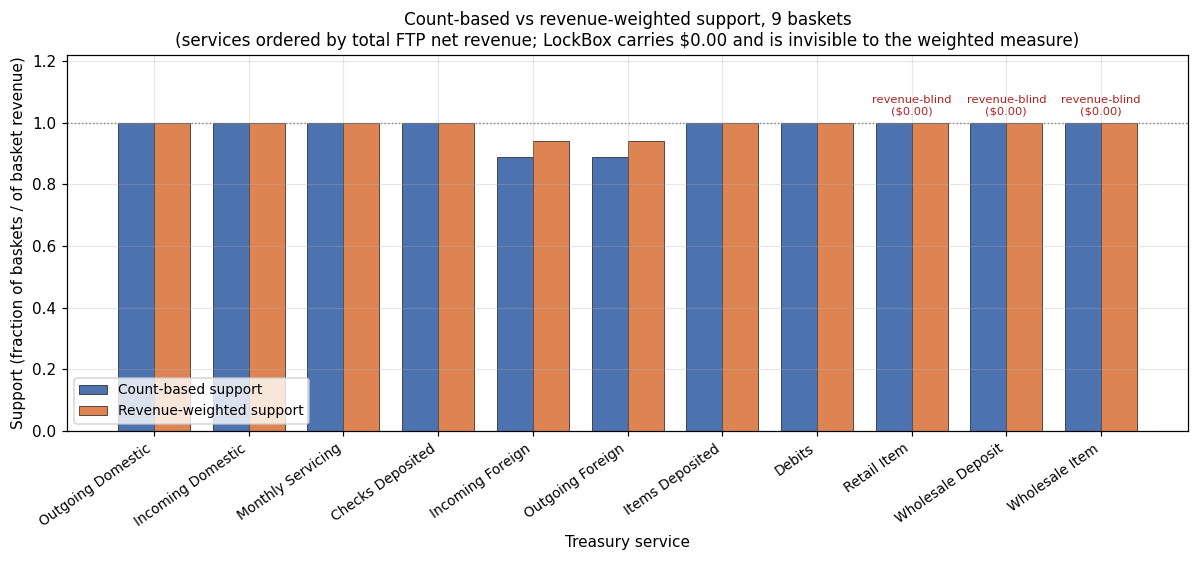

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.2))
order = support.index.tolist()
x = np.arange(len(order))
width = 0.38
ax.bar(x - width / 2, support.loc[order, "count_support"], width,
       label="Count-based support", color="#4C72B0", edgecolor="black", linewidth=0.4)
ax.bar(x + width / 2, support.loc[order, "rw_support"], width,
       label="Revenue-weighted support", color="#DD8452", edgecolor="black", linewidth=0.4)
for xi, name in zip(x, order):
    if support.loc[name, "revenue_blind"]:
        ax.annotate("revenue-blind\n($0.00)", (xi, 1.02), ha="center", va="bottom",
                    fontsize=7.5, color="#B22222")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=35, ha="right", fontsize=9)
ax.set_ylim(0, 1.22)
ax.set_ylabel("Support (fraction of baskets / of basket revenue)")
ax.set_xlabel("Treasury service")
ax.set_title("Count-based vs revenue-weighted support, 9 baskets\n"
             "(services ordered by total FTP net revenue; LockBox carries $0.00 and is "
             "invisible to the weighted measure)", fontsize=11)
ax.axhline(1.0, color="grey", linestyle=":", linewidth=0.9)
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## Revenue concentration — Lorenz curves and Gini

Gini is computed twice: across the 11 **services** (is revenue carried by a few products?) and
across the 9 **relationships** (is it carried by a few clients?). Zero-revenue services are
*included*, which is the honest choice — excluding them would flatter the service-level
concentration figure.

In [7]:
def lorenz_points(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return cumulative population and cumulative revenue-share points.

    The origin (0, 0) is included. An all-zero input is defined as the line of
    equality rather than raising, which keeps the LockBox case from producing a
    divide-by-zero.
    """
    v = np.sort(np.asarray(values, dtype=float))
    if v.size == 0:
        raise ValueError("no values supplied")
    if (v < 0).any():
        raise ValueError("Lorenz curve is undefined for negative values")
    total = v.sum()
    population = np.linspace(0.0, 1.0, v.size + 1)
    if total <= 0:
        return population, population
    return population, np.concatenate([[0.0], np.cumsum(v) / total])


def gini(values: np.ndarray) -> float:
    """Gini coefficient; 0.0 for an all-zero (perfectly equal) distribution."""
    population, cumulative = lorenz_points(values)
    return float(max(0.0, 1.0 - 2.0 * _TRAPZ(cumulative, population)))


service_vals = support["service_revenue"].to_numpy()
relation_vals = basket_rev.to_numpy()
gini_service = gini(service_vals)
gini_relation = gini(relation_vals)

top2 = support["revenue_share"].nlargest(2)
print(f"Gini across {len(service_vals)} services      : {gini_service:.3f}")
print(f"Gini across {len(relation_vals)} relationships : {gini_relation:.3f}")
print(f"top-2 services = {top2.sum():.1%} of revenue ({', '.join(top2.index)})")
print(f"zero-revenue services: {int(support['revenue_blind'].sum())} of {len(support)}")
print(f"LockBox-only Gini (all-zero guard): {gini(np.zeros(3)):.3f}")

Gini across 11 services      : 0.655
Gini across 9 relationships : 0.085
top-2 services = 72.1% of revenue (Outgoing Domestic, Incoming Domestic)
zero-revenue services: 3 of 11
LockBox-only Gini (all-zero guard): 0.000


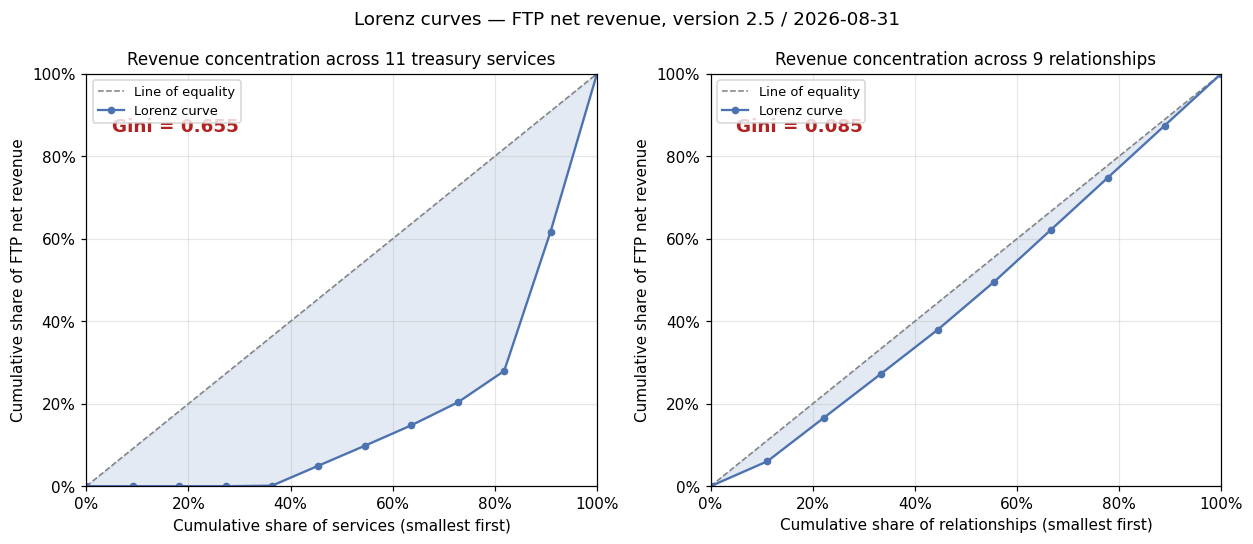

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5)) 
for ax, vals, g, unit, what in (
    (axes[0], service_vals, gini_service, "services", f"{len(service_vals)} treasury services"),
    (axes[1], relation_vals, gini_relation, "relationships", f"{len(relation_vals)} relationships"),
):
    population, cumulative = lorenz_points(vals)
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1,
            label="Line of equality")
    ax.plot(population, cumulative, marker="o", markersize=4, color="#4C72B0",
            label="Lorenz curve")
    ax.fill_between(population, cumulative, population, color="#4C72B0", alpha=0.15)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel(f"Cumulative share of {unit} (smallest first)")
    ax.set_ylabel("Cumulative share of FTP net revenue")
    ax.set_title(f"Revenue concentration across {what}", fontsize=11)
    ax.annotate(f"Gini = {g:.3f}", (0.05, 0.86), fontsize=12, fontweight="bold",
                color="#B22222")
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.legend(loc="upper left", fontsize=8.5)
fig.suptitle("Lorenz curves — FTP net revenue, version 2.5 / 2026-08-31", fontsize=12)
fig.tight_layout()
plt.show()

Service revenue is **highly concentrated**: the two domestic-wire services carry the clear majority
of the book, and three of eleven services carry nothing at all. Relationship revenue is by contrast
**almost flat** — unsurprising given eight baskets hold the same services and several are near-clones
of one another (`Cape Lookout Marine`, `… V3`, `… V4` carry identical revenue). The low
relationship-level Gini is a property of this nine-row sample, not evidence that the real book is
evenly distributed.

## Per-basket revenue profile

Revenue by service by relationship. This is the only view in the investigation that distinguishes
the baskets from each other at all — by set membership eight of them are indistinguishable.

In [9]:
profile = (
    rows.pivot_table(index=BASKET_KEY, columns=ITEM_GRAIN, values=REVENUE_COL,
                     aggfunc="sum", fill_value=0.0)
    .reindex(index=matrix.index, columns=support.index, fill_value=0.0)
)
profile.index = [labels.get(k, k) for k in profile.index]
profile = profile.loc[profile.sum(axis=1).sort_values(ascending=False).index]

summary = pd.DataFrame(
    {
        "total_revenue": profile.sum(axis=1),
        "n_services": matrix.sum(axis=1).rename(index=labels).reindex(profile.index),
    }
)
summary["revenue_weight_w"] = summary["total_revenue"] / total_rev
display(summary.style.format({"total_revenue": "${:,.2f}",
                              "revenue_weight_w": "{:.2%}"}))
display(profile.style.format("${:,.2f}"))

,total_revenue,n_services,revenue_weight_w
Cape Lookout Marine V4,"$8,390.61",11,12.61%
Acme Supply Inc. - Integrated,"$8,390.61",11,12.61%
Cape Lookout Marine,"$8,390.61",11,12.61%
Cape Lookout Marine V3,"$8,390.61",11,12.61%
Currituck Properties,"$7,775.43",11,11.68%
Coastal Realty & Co.,"$7,110.22",11,10.68%
Charles & Laura Design Studios,"$7,049.27",11,10.59%
"Bohannon Development, LLC","$7,049.27",11,10.59%
OBX Integrated & Co.,"$4,018.95",9,6.04%


TREASURY_SERVICE_NAME,Outgoing Domestic,Incoming Domestic,Monthly Servicing,Checks Deposited,Incoming Foreign,Outgoing Foreign,Items Deposited,Debits,Retail Item,Wholesale Deposit,Wholesale Item
Cape Lookout Marine V4,"$2,972.50","$2,905.56",$630.36,$477.01,$490.56,$503.44,$402.50,$8.68,$0.00,$0.00,$0.00
Acme Supply Inc. - Integrated,"$2,972.50","$2,905.56",$630.36,$477.01,$490.56,$503.44,$402.50,$8.68,$0.00,$0.00,$0.00
Cape Lookout Marine,"$2,972.50","$2,905.56",$630.36,$477.01,$490.56,$503.44,$402.50,$8.68,$0.00,$0.00,$0.00
Cape Lookout Marine V3,"$2,972.50","$2,905.56",$630.36,$477.01,$490.56,$503.44,$402.50,$8.68,$0.00,$0.00,$0.00
Currituck Properties,"$2,972.50","$2,905.56",$346.08,$321.95,$490.56,$503.44,$226.66,$8.68,$0.00,$0.00,$0.00
Coastal Realty & Co.,"$2,972.50","$2,138.50",$630.36,$437.85,$280.32,$235.17,$402.50,$13.02,$0.00,$0.00,$0.00
Charles & Laura Design Studios,"$2,913.05","$2,138.50",$630.36,$436.35,$280.32,$235.17,$402.50,$13.02,$0.00,$0.00,$0.00
"Bohannon Development, LLC","$2,913.05","$2,138.50",$630.36,$436.35,$280.32,$235.17,$402.50,$13.02,$0.00,$0.00,$0.00
OBX Integrated & Co.,"$1,819.17","$1,545.02",$315.18,$155.06,$0.00,$0.00,$175.84,$8.68,$0.00,$0.00,$0.00


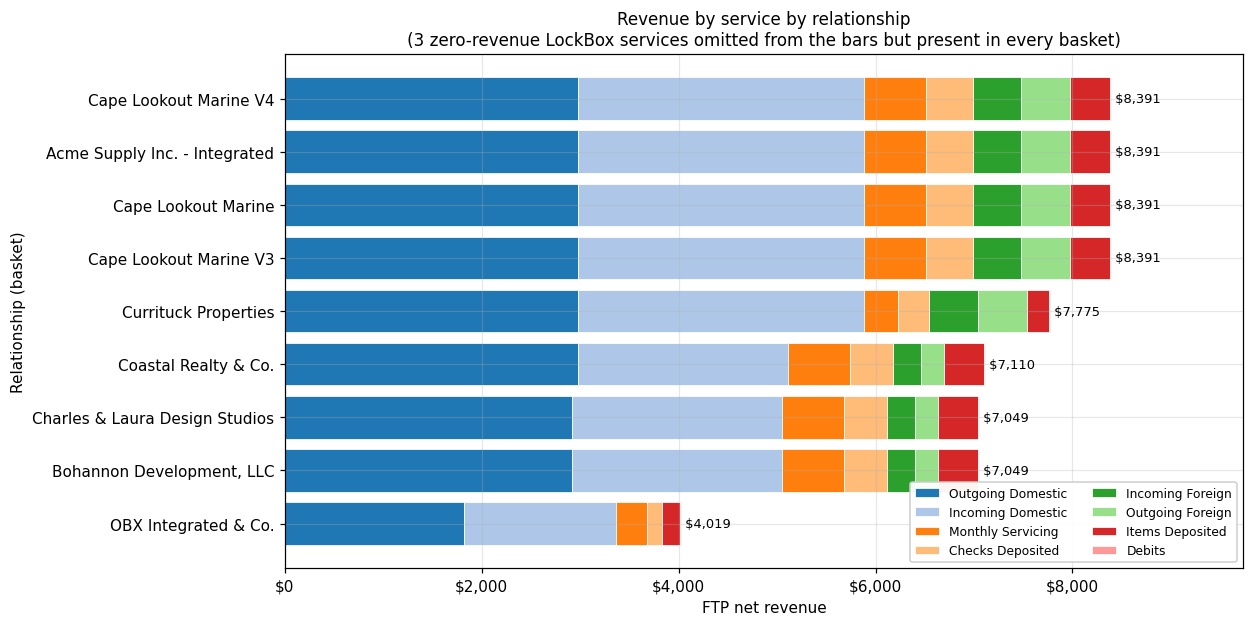

zero-revenue (revenue-blind) services present in all baskets: ['Retail Item', 'Wholesale Deposit', 'Wholesale Item']


In [10]:
paying = [c for c in profile.columns if profile[c].sum() > 0]
blind = [c for c in profile.columns if profile[c].sum() == 0]
fig, ax = plt.subplots(figsize=(11.5, 5.8))
bottom = np.zeros(len(profile))
cmap = plt.get_cmap("tab20")
for idx, svc in enumerate(paying):
    vals = profile[svc].to_numpy(dtype=float)
    ax.barh(profile.index, vals, left=bottom, label=svc,
            color=cmap(idx % 20), edgecolor="white", linewidth=0.5)
    bottom += vals
ax.set_xlabel("FTP net revenue")
ax.set_ylabel("Relationship (basket)")
ax.set_title("Revenue by service by relationship\n"
             f"({len(blind)} zero-revenue LockBox services omitted from the bars but "
             "present in every basket)", fontsize=11)
ax.xaxis.set_major_formatter(MONEY)
ax.invert_yaxis()
for y, tot in enumerate(profile.sum(axis=1).to_numpy()):
    ax.annotate(f" ${tot:,.0f}", (tot, y), va="center", fontsize=8.5)
ax.set_xlim(0, float(profile.sum(axis=1).max()) * 1.16)
ax.legend(fontsize=8, ncol=2, loc="lower right", framealpha=0.95)
fig.tight_layout()
plt.show()
print("zero-revenue (revenue-blind) services present in all baskets:", blind)

`OBX Integrated & Co.` is the lowest-revenue relationship *and* the only one missing services. The
remaining eight differ only in revenue magnitude, not in composition — and three of them
(`Cape Lookout Marine` and its V3/V4 variants) are revenue-identical, which looks like test or
duplicate data and is a further reason to treat relationship-level dispersion here as unreliable.

## Cross-sell value sizing — the one genuine gap

There is exactly **one** product gap in this snapshot: `OBX Integrated & Co.` holds neither
`Incoming Foreign` nor `Outgoing Foreign`, while all eight other relationships hold both. The two
services co-occur perfectly (8/8, Jaccard 1.0).

Sizing method: take the observed `Incoming Foreign` + `Outgoing Foreign` revenue among those 8 peer
relationships and use the peer **mean** as a point estimate, with the peer min and max as the
observed range. The peer distribution is plotted so the spread is visible rather than hidden behind
a single number.

**Caveats, which are load-bearing:**

- This is **one relationship**, not a cross-sell programme. Eight of nine relationships already
  hold both services; there is no population of prospects here to generalise to.
- The estimate assumes `OBX` would generate peer-like foreign-wire revenue. Nothing in the snapshot
  supports that assumption — `ACTUAL_MONTHLY_UNITS` and `YEARLY_VOLUME` are NULL, so there is no way
  to scale the estimate to OBX's actual transaction behaviour. OBX is the *smallest* basket by
  revenue, which argues the mean likely overstates it.
- Peer n = 8, and the peer values take only two distinct levels, so the "distribution" is a
  two-point distribution, not a sample with meaningful shape.
- This is a single-period snapshot. No trend, no persistence, no churn risk.

In [11]:
gap_mask = rows[ITEM_GRAIN].isin(GAP_SERVICES)
peer_by_rel = rows[gap_mask].pivot_table(
    index=BASKET_KEY, columns=ITEM_GRAIN, values=REVENUE_COL,
    aggfunc="sum", fill_value=0.0,
)
peer_by_rel.index = [labels.get(k, k) for k in peer_by_rel.index]
peer_by_rel["combined"] = peer_by_rel[GAP_SERVICES].sum(axis=1)
peer_by_rel = peer_by_rel.sort_values("combined", ascending=False)

assert GAP_RELATIONSHIP not in peer_by_rel.index, (
    "gap relationship unexpectedly holds the foreign-wire services"
)
n_peers = len(peer_by_rel)
per_service_mean = peer_by_rel[GAP_SERVICES].mean()
opportunity = float(per_service_mean.sum())
obx_rev = float(basket_rev.rename(index=labels).get(GAP_RELATIONSHIP, np.nan))
if not obx_rev > 0:
    raise ValueError(f"{GAP_RELATIONSHIP} has no revenue; cannot express a ratio")

display(peer_by_rel.style.format("${:,.2f}"))
print(f"peer relationships holding both services: {n_peers}")
for svc, val in per_service_mean.items():
    print(f"  mean {svc:<18}: ${val:,.2f}")
print(f"\nsized opportunity (peer mean, combined) : ${opportunity:,.2f}")
print(f"observed peer range (combined)          : "
      f"${peer_by_rel['combined'].min():,.2f} - ${peer_by_rel['combined'].max():,.2f}")
print(f"{GAP_RELATIONSHIP} current revenue        : ${obx_rev:,.2f}")
print(f"opportunity as % of its current revenue : {opportunity / obx_rev:.1%}")
print(f"opportunity as % of total book revenue  : {opportunity / total_rev:.2%}")

TREASURY_SERVICE_NAME,Incoming Foreign,Outgoing Foreign,combined
Cape Lookout Marine V4,$490.56,$503.44,$994.00
Acme Supply Inc. - Integrated,$490.56,$503.44,$994.00
Cape Lookout Marine,$490.56,$503.44,$994.00
Cape Lookout Marine V3,$490.56,$503.44,$994.00
Currituck Properties,$490.56,$503.44,$994.00
Charles & Laura Design Studios,$280.32,$235.17,$515.49
Coastal Realty & Co.,$280.32,$235.17,$515.49
"Bohannon Development, LLC",$280.32,$235.17,$515.49


peer relationships holding both services: 8
  mean Incoming Foreign  : $411.72
  mean Outgoing Foreign  : $402.84

sized opportunity (peer mean, combined) : $814.56
observed peer range (combined)          : $515.49 - $994.00
OBX Integrated & Co. current revenue        : $4,018.95
opportunity as % of its current revenue : 20.3%
opportunity as % of total book revenue  : 1.22%


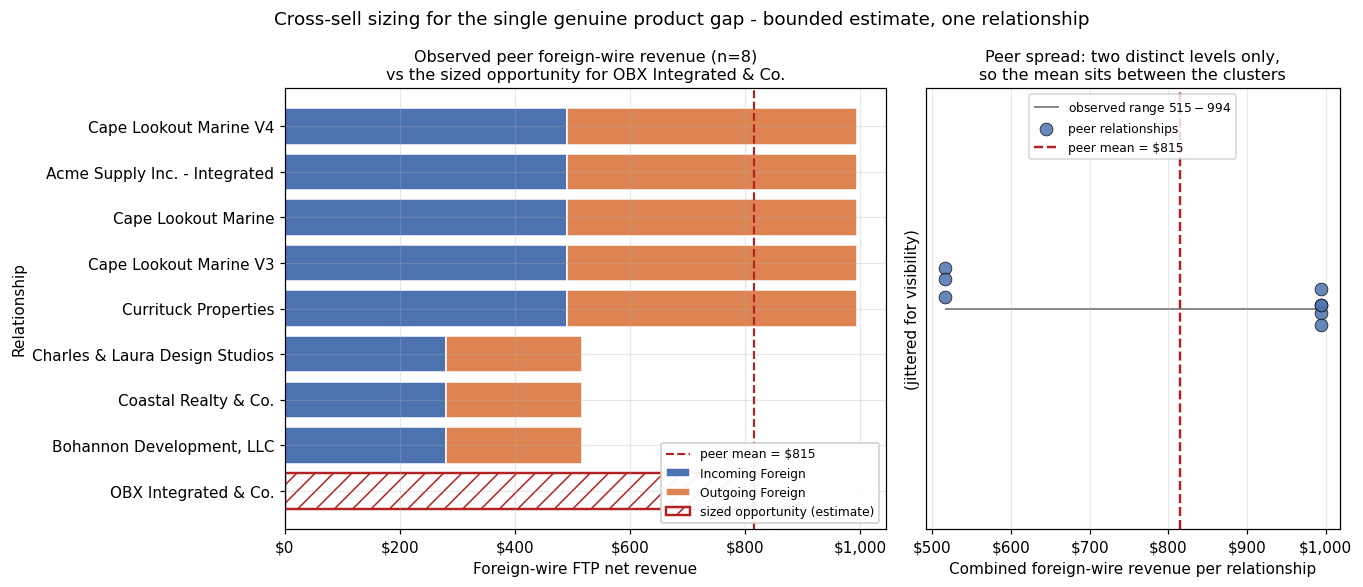

In [12]:
fig, (axl, axr) = plt.subplots(1, 2, figsize=(12.5, 5.4),
                               gridspec_kw={"width_ratios": [1.45, 1]})

combined = peer_by_rel["combined"]
axl.barh(peer_by_rel.index, peer_by_rel[GAP_SERVICES[0]], color="#4C72B0",
         edgecolor="white", label=GAP_SERVICES[0])
axl.barh(peer_by_rel.index, peer_by_rel[GAP_SERVICES[1]],
         left=peer_by_rel[GAP_SERVICES[0]], color="#DD8452", edgecolor="white",
         label=GAP_SERVICES[1])
axl.barh([GAP_RELATIONSHIP], [opportunity], color="none", edgecolor="#B22222",
         hatch="//", linewidth=1.6, label="sized opportunity (estimate)")
axl.axvline(opportunity, color="#B22222", linestyle="--", linewidth=1.4,
            label=f"peer mean = ${opportunity:,.0f}")
axl.set_xlabel("Foreign-wire FTP net revenue")
axl.set_ylabel("Relationship")
axl.set_title(f"Observed peer foreign-wire revenue (n={n_peers})\n"
              f"vs the sized opportunity for {GAP_RELATIONSHIP}", fontsize=10.5)
axl.xaxis.set_major_formatter(MONEY)
axl.invert_yaxis()
axl.legend(fontsize=8, loc="lower right", framealpha=0.95)

jitter = np.random.default_rng(0).normal(0.0, 0.035, n_peers)
axr.hlines(0, combined.min(), combined.max(), color="grey", linewidth=1.2, zorder=1,
           label=f"observed range ${combined.min():,.0f}-${combined.max():,.0f}")
axr.scatter(combined.to_numpy(), jitter, s=70, color="#4C72B0", alpha=0.85,
            edgecolor="black", linewidth=0.5, zorder=3, label="peer relationships")
axr.axvline(opportunity, color="#B22222", linestyle="--", linewidth=1.6,
            label=f"peer mean = ${opportunity:,.0f}")
axr.set_yticks([])
axr.set_ylim(-0.25, 0.25)
axr.set_xlabel("Combined foreign-wire revenue per relationship")
axr.set_ylabel("(jittered for visibility)")
axr.set_title("Peer spread: two distinct levels only,\nso the mean sits between the clusters",
              fontsize=10.5)
axr.xaxis.set_major_formatter(MONEY)
axr.legend(fontsize=8, loc="upper center")

fig.suptitle("Cross-sell sizing for the single genuine product gap - bounded estimate, "
             "one relationship", fontsize=12)
fig.tight_layout()
plt.show()

## What revenue weighting would reveal at scale

With a basket population in the thousands rather than nine, and with non-degenerate membership,
this same machinery becomes genuinely informative:

- **Revenue-weighted support and lift** would separate *common* bundles from *valuable* bundles.
  A pair held by 5% of relationships that accounts for 30% of revenue is a different proposition
  from one held by 40% of relationships worth 5% — count-based MBA ranks them identically on
  frequency and misses the distinction entirely.
- **Revenue-weighted association rules** would prioritise cross-sell targets by expected value
  rather than by probability of acceptance, which is the quantity a treasury sales team actually
  optimises.
- **Lorenz / Gini over a real book** would quantify concentration risk — how much of the franchise
  depends on a handful of services or clients — and could be tracked over successive
  `DATE_PARTITION` values to detect drift.
- **Peer-revenue gap sizing** becomes a ranked pipeline once there are many gap relationships, with
  peer cohorts matched on size and segment instead of "everyone else".

## What is NOT concludable from this snapshot

Stated plainly, because the preceding numbers are easy to over-read:

1. **No association structure.** Eight of nine baskets are identical; lift is only ever 1.0 or
   1.125; no pair can reach significance at n = 9. Revenue weighting adds variance to the measures
   but **not** to the co-occurrence structure. Any "revenue-weighted lift" here is a restatement of
   revenue dispersion across baskets.
2. **Nothing about LockBox.** All three LockBox services carry exactly \$0.00. Revenue-weighted
   analysis cannot see them, so this notebook is silent on them by construction — not because they
   lack value.
3. **No cross-sell programme.** There is one gap relationship. A single observation does not
   support a portfolio strategy, a prioritised pipeline, or a revenue target. The sized figure is
   an upper-leaning estimate for one named client, contingent on peer-like behaviour that the data
   cannot confirm.
4. **No unit economics.** `ACTUAL_MONTHLY_UNITS`, `WAIVED_UNITS` and `YEARLY_VOLUME` are NULL.
   No price-per-item, no waiver leakage, no volume-based forecast.
5. **No second revenue view.** `FTP_NET_REVENUE` and `STRATEGIC_NET_REVENUE` are identical
   row-for-row. Any analysis presenting them as corroborating signals would be double-counting a
   single measure.
6. **No trend.** One `DATE_PARTITION`. Levels only; no direction, no persistence.
7. **Provisional groupings.** The service-group mapping comes from `INTEGRATION_TESTING`, not
   production, so every group-level statement is contingent on that mapping being correct.

The deliverable here is the reusable revenue-weighting methodology, not findings about this book.